In [2]:
#Importing Libraries
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
#Load the CSV files
orders = pd.read_csv("olist_orders_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")

categories = pd.read_csv(
    "product_category_name_translation.csv"
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [4]:
#Check the dataset
print("Orders:", orders.shape)
print("Order Items:", items.shape)
print("Products:", products.shape)
print("Customers:", customers.shape)

display(orders.head())

Orders: (99441, 8)
Order Items: (112650, 7)
Products: (32951, 9)
Customers: (99441, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [5]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


In [6]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [7]:
datasets = {
    "orders": orders,
    "items": items,
    "products": products,
    "customers": customers,
    "categories": categories
}

for name, df in datasets.items():
    print(f"\n--- {name.upper()} ---")
    missing = df.isnull().sum()
    print(missing[missing > 0])


--- ORDERS ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

--- ITEMS ---
Series([], dtype: int64)

--- PRODUCTS ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

--- CUSTOMERS ---
Series([], dtype: int64)

--- CATEGORIES ---
Series([], dtype: int64)


In [8]:
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )

orders: 0 duplicate rows
items: 0 duplicate rows
products: 0 duplicate rows
customers: 0 duplicate rows
categories: 0 duplicate rows


In [10]:
items["price"] = pd.to_numeric(
    items["price"], errors="coerce"
)

items["freight_value"] = pd.to_numeric(
    items["freight_value"], errors="coerce"
)

print("Missing prices:", items["price"].isnull().sum())
print("Missing freight:", items["freight_value"].isnull().sum())
print("Negative prices:", (items["price"] < 0).sum())
print("Negative freight:", (items["freight_value"] < 0).sum())

Missing prices: 0
Missing freight: 0
Negative prices: 0
Negative freight: 0


In [11]:
orders_clean = orders.copy()
items_clean = items.copy()
products_clean = products.copy()
customers_clean = customers.copy()
categories_clean = categories.copy()

print("Cleaned dataset copies created!")

Cleaned dataset copies created!


In [12]:
print("Orders:", orders_clean.shape)
print("Items:", items_clean.shape)
print("Products:", products_clean.shape)
print("Customers:", customers_clean.shape)
print("Categories:", categories_clean.shape)

Orders: (99441, 8)
Items: (112650, 7)
Products: (32951, 9)
Customers: (99441, 5)
Categories: (71, 2)


In [13]:
print(orders_clean["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [14]:
delivered_orders = orders_clean[
    orders_clean["order_status"] == "delivered"
]

sales_data = delivered_orders.merge(
    items_clean,
    on="order_id",
    how="inner"
)

total_revenue = sales_data["price"].sum()

print("Total Revenue:", round(total_revenue, 2))
print("Delivered Orders:", delivered_orders["order_id"].nunique())
print("Items Sold:", len(sales_data))

Total Revenue: 13221498.11
Delivered Orders: 96478
Items Sold: 110197


In [15]:
average_order_value = (
    total_revenue / delivered_orders["order_id"].nunique()
)

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 137.04


In [16]:

# Extract month from the order purchase date
sales_data["purchase_month"] = (
    sales_data["order_purchase_timestamp"]
    .dt.to_period("M")
)

# Calculate monthly revenue
monthly_sales = (
    sales_data.groupby("purchase_month")["price"]
    .sum()
    .reset_index()
)

monthly_sales.columns = ["Month", "Revenue"]

print(monthly_sales.head(10))


     Month    Revenue
0  2016-09     134.97
1  2016-10   40325.11
2  2016-12      10.90
3  2017-01  111798.36
4  2017-02  234223.40
5  2017-03  359198.85
6  2017-04  340669.68
7  2017-05  489338.25
8  2017-06  421923.37
9  2017-07  481604.52


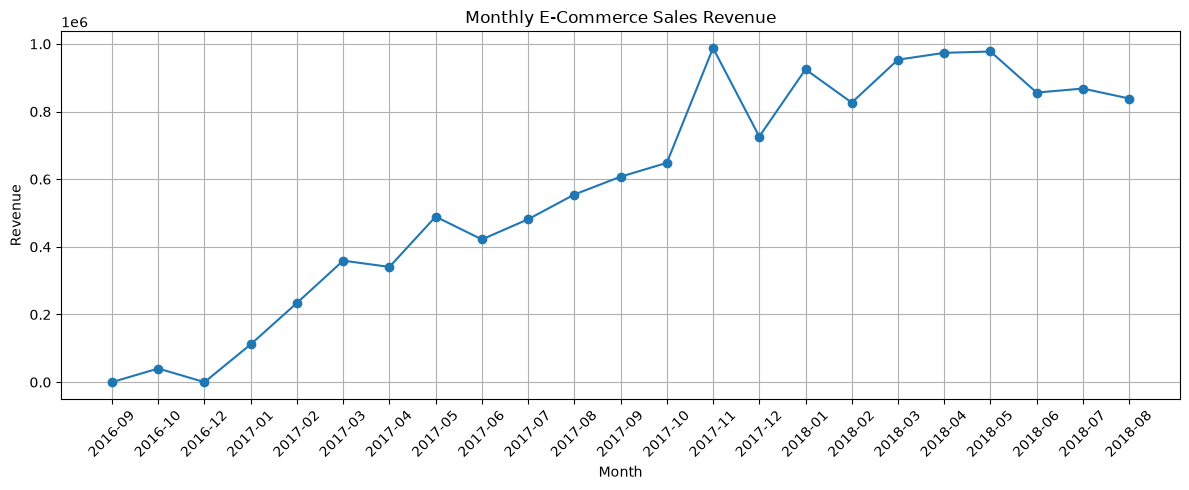

In [17]:

plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"].astype(str),
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly E-Commerce Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [18]:

best_month = monthly_sales.loc[
    monthly_sales["Revenue"].idxmax()
]

print("Best sales month:", best_month["Month"])
print("Revenue:", round(best_month["Revenue"], 2))


Best sales month: 2017-11
Revenue: 987765.37


In [19]:

# Merge sales data with product information
category_sales = sales_data.merge(
    products_clean[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Add English category names
category_sales = category_sales.merge(
    categories_clean,
    on="product_category_name",
    how="left"
)

# Calculate revenue by category
category_revenue = (
    category_sales.groupby("product_category_name_english")["price"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 product categories by revenue:")
print(category_revenue.head(10))


Top 10 product categories by revenue:
product_category_name_english
health_beauty            1233131.72
watches_gifts            1166176.98
bed_bath_table           1023434.76
sports_leisure            954852.55
computers_accessories     888724.61
furniture_decor           711927.69
housewares                615628.69
cool_stuff                610204.10
auto                      578966.65
toys                      471286.48
Name: price, dtype: float64


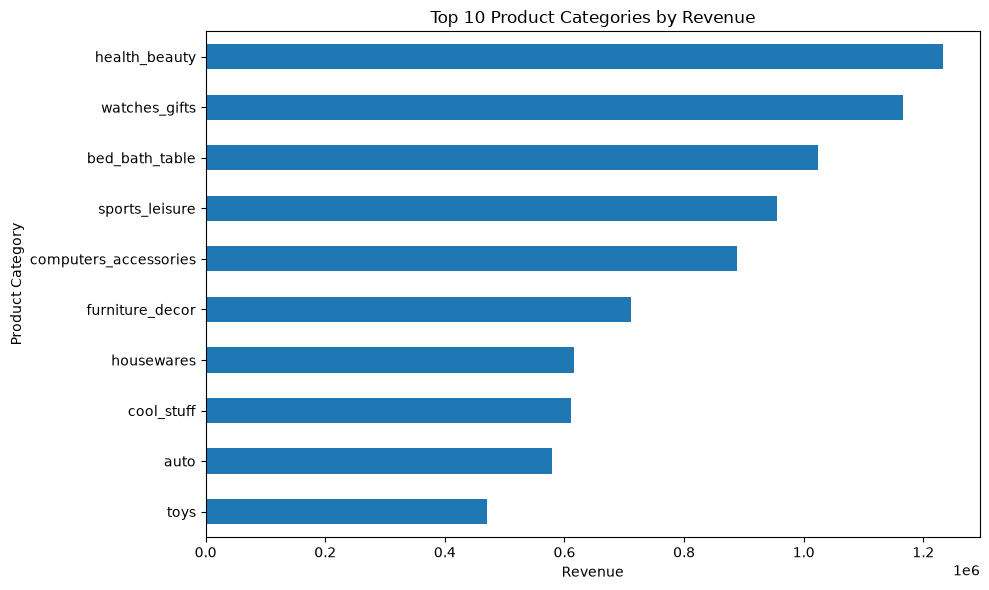

In [20]:

top_categories = category_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))

top_categories.plot(kind="barh")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


In [21]:

# Create an SQLite database
conn = sqlite3.connect("ecommerce_analysis.db")

# Load cleaned datasets into SQL tables
orders_clean.to_sql(
    "orders", conn, if_exists="replace", index=False
)

items_clean.to_sql(
    "items", conn, if_exists="replace", index=False
)

products_clean.to_sql(
    "products", conn, if_exists="replace", index=False
)

categories_clean.to_sql(
    "categories", conn, if_exists="replace", index=False
)

print("SQL tables created successfully!")


SQL tables created successfully!


In [22]:

query = """
SELECT order_status, COUNT(*) AS total_orders
FROM orders
GROUP BY order_status
ORDER BY total_orders DESC;
"""

status_summary = pd.read_sql_query(query, conn)
display(status_summary)


,order_status,total_orders
0,delivered,96478
1,shipped,1107
2,canceled,625
3,unavailable,609
4,invoiced,314
5,processing,301
6,created,5
7,approved,2


In [23]:

query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    ROUND(SUM(i.price), 2) AS revenue
FROM orders o
JOIN items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY strftime('%Y-%m', o.order_purchase_timestamp)
ORDER BY month;
"""

sql_monthly_sales = pd.read_sql_query(query, conn)
display(sql_monthly_sales.head(10))


,month,revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


In [24]:

query = """
SELECT
    COALESCE(c.product_category_name_english,
             p.product_category_name,
             'unknown') AS category,
    ROUND(SUM(i.price), 2) AS revenue
FROM orders o
JOIN items i ON o.order_id = i.order_id
JOIN products p ON i.product_id = p.product_id
LEFT JOIN categories c
    ON p.product_category_name = c.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY category
ORDER BY revenue DESC
LIMIT 10;
"""

sql_top_categories = pd.read_sql_query(query, conn)
display(sql_top_categories)


,category,revenue
0,health_beauty,1233131.72
1,watches_gifts,1166176.98
2,bed_bath_table,1023434.76
3,sports_leisure,954852.55
4,computers_accessories,888724.61
5,furniture_decor,711927.69
6,housewares,615628.69
7,cool_stuff,610204.10
8,auto,578966.65
9,toys,471286.48


In [25]:

query = """
SELECT
    strftime('%Y-%m', o.order_purchase_timestamp) AS month,
    ROUND(SUM(i.price), 2) AS revenue
FROM orders o
JOIN items i ON o.order_id = i.order_id
WHERE o.order_status = 'delivered'
GROUP BY month
ORDER BY revenue DESC
LIMIT 1;
"""

best_month_sql = pd.read_sql_query(query, conn)
display(best_month_sql)


,month,revenue
0,2017-11,987765.37
